In [1]:
from langgraph.graph import StateGraph , START,END
from typing import TypedDict,List
from langchain_openai.chat_models import ChatOpenAI
from dotenv import load_dotenv

load_dotenv()

True

# Tabel of contents


1. Sequential workflow (without LLM)
2. Sequential workflow (with LLM)

# 1) Sequential workflow (without LLM)

**problem statement** :  Given the physics, chemistry, and math marks, we have to calculate the average via a sequential workflow. 

In [2]:
class Student(TypedDict):
    name :  str 
    age :  int 
    physics :  float
    chemistry :  float 
    maths :  float 
    avg :  int  

In [3]:
def calculate_avg(state :  Student) ->  Student :
    
    state["avg"] =  (state["physics"] +  state["chemistry"] +  state["maths"]) /3 
    
    return state 
    

In [4]:
graph   = StateGraph(Student)


graph.add_node("calculate_avg",calculate_avg)


graph.add_edge(START,"calculate_avg")
graph.add_edge("calculate_avg",END)


workflow =  graph.compile()





In [5]:
data =  {"name":"rishabh","age":19,"physics":19.0,"chemistry":12.0,"maths":20.3}

final_state =  workflow.invoke(data)

print(final_state)

{'name': 'rishabh', 'age': 19, 'physics': 19.0, 'chemistry': 12.0, 'maths': 20.3, 'avg': 17.099999999999998}


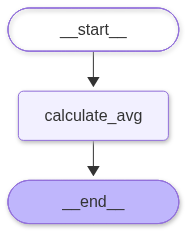

In [6]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

# 2)  Sequential workflow (with LLM)

**problem statement** : A context will be given, and the LM model has to generate the business ideas on the context using the sequential workflow. 

In [11]:

class Suggest_ideas(TypedDict):
    
    context : str 
    ideas :  str 
    
    
llm  =  ChatOpenAI(model="gpt-4.1-mini")

In [12]:
def suggest(state : Suggest_ideas) ->  Suggest_ideas:
    
    prompt = f"suggest  5 ideas on {state['context']}"
    state["ideas"] =  llm.invoke(prompt).content
    return state 

In [13]:
graph = StateGraph(Suggest_ideas)

graph.add_node("suggest",suggest)


graph.add_edge(START,"suggest")
graph.add_edge("suggest",END)


workflow =  graph.compile()



In [15]:
data = "Tech business"

final_state =  workflow.invoke({"context":data})
print(final_state["ideas"])


Certainly! Here are 5 tech business ideas you might consider:

1. **AI-Powered Personalization Platform**  
Develop a platform that uses artificial intelligence to deliver highly personalized content, product recommendations, or marketing strategies for e-commerce websites, helping businesses improve customer engagement and sales.

2. **Remote Work Collaboration Tools**  
Create innovative software that enhances remote team collaboration, such as virtual whiteboards, project management apps with AI task prioritization, or immersive VR meeting environments.

3. **Cybersecurity Solutions for SMEs**  
Offer tailored cybersecurity products and services designed specifically for small and medium-sized enterprises, including affordable threat detection, response tools, and employee training programs.

4. **Health Tech Wearables and Data Analytics**  
Design wearable devices paired with a data analytics platform to monitor health metrics in real-time, targeting specific conditions like diabet

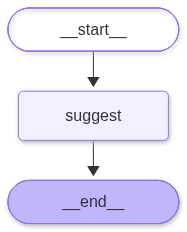

In [16]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())